## Business Understanding:

### Business Goal: Price Estimation of Pre-owned Cars

#### Client Reference: CARS4(Application) / End User


**Business goal affecting features:**

Features that can affect price estimation
- Brand
- Model
- Make Year
- Transmission
- Date of registration
- Engine Capacity
- KMDriven
- Fuel Type
- Ownership

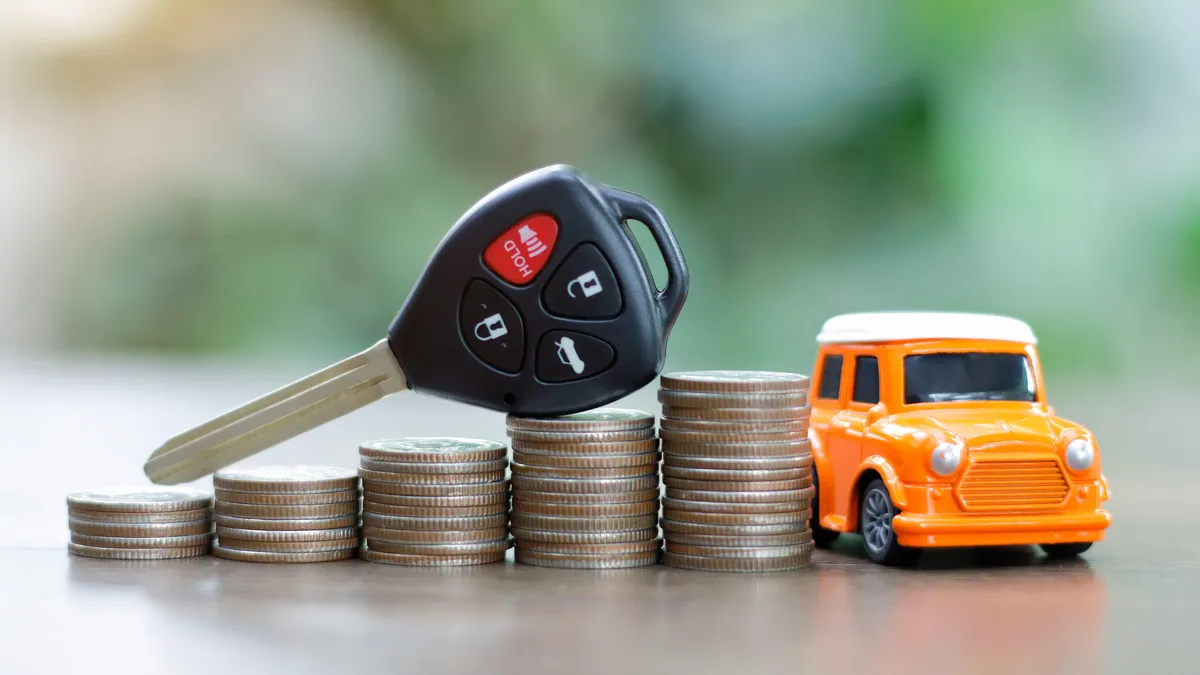

### TOC <a id='menu'>
    
* [0. Data](#data)
* [1. Data Validation](#Dval)
* [2. EDA](#eda)
    * [2.1 Uni-Variate Analysis](#uva)
    * [2.2 Bi-Variate Analysis](#bva)
    * [2.3 Multi-Variate Analysis](#mva)
* [3. Missing Values & Outliers](#Naou)
    * [3.1 Missing Values](#mv)
    * [3.2 Outliers](#out)
* [4. Predictive Modelling](#pm)
    * [4.1 x & y](#xy)
    * [4.2 Feature Engineering](#fe)
    * [4.3 Train-Test Split](#tnts)
    * [4.4 Training Model](#tm)
* [5. Realtime Predictions](#pred)

### 0. Data Collection <a id='data'>
[Back to Top](#menu)

- We have collected the primary data by using the method called, Web Scraping from the client site(CARS24)

**Libraries Used**

- Pandas
- Numpy

**Visualisation Libraries Used**

- Seaborn
- Matplotlib
- Plotly

**Data Loading**

In [1]:
import pandas as pd

import numpy as np

import warnings
warnings.filterwarnings("ignore")

In [2]:
#Visualisation Libraries

import matplotlib.pyplot as plt

import seaborn as sns

import plotly.express as px

from plotly.offline import init_notebook_mode
init_notebook_mode(connected=True)

In [3]:
data = pd.read_csv("cars24validateddata.csv")

In [4]:
data.head(2)

,Brand,Model,Makeyear,Reg month,Reg year,Regnumber,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype,Price(lakhs)
0,honda,city,2015,may,2015,mh01-by4993,1497.0,Available,yes,manual,76749.0,2,petrol,4.85
1,maruti,swift,2015,mar,2015,mh01-by3310,1197.0,Available,yes,manual,76928.0,2,petrol,3.87


In [5]:
data.columns

Index(['Brand', 'Model', 'Makeyear', 'Reg month', 'Reg year', 'Regnumber',
       'Enginecapacity', 'Insurance', 'Sparekey', 'Transmission', 'KMDriven',
       'Ownership', 'Fueltype', 'Price(lakhs)'],
      dtype='object')

- We have a counnt of 593 rows and 14 columns

- Columns Info:

SI.NO.|Columns Nmae|Descrption
-----|----------|---------------
1| Brand | Brand/Manufacturer name
2| Model | Model of the car
3| MakeYear | Manufacturing year of the car
4| Reg month | Registration month of the car
5| Reg Year | Registration year of the car
6| Reg Number | Registration number of the car/License plate no.
7| Engine Capacity | Capacity of the engine
8| Insurance | says about the avaialability of the car insuarance
9| SpareKey | Sys about the availability of the extra key of car
10| Transmission | Transmission of the car
11| KMDriven | Number of KM's were the car driven
12| Ownership | Number of owner/persons previously used/owned
13|FuelType | Type of the fuel
14| Price | Selling cost of the car

### Basic Checks

In [6]:
data.shape

(593, 14)

In [7]:
print("First Five Rows of Dataset:")
display(data.head())

print("Last Five Rows of Dataset:")
display(data.tail())

First Five Rows of Dataset:


,Brand,Model,Makeyear,Reg month,Reg year,Regnumber,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype,Price(lakhs)
0,honda,city,2015,may,2015,mh01-by4993,1497.0,Available,yes,manual,76749.0,2,petrol,4.85
1,maruti,swift,2015,mar,2015,mh01-by3310,1197.0,Available,yes,manual,76928.0,2,petrol,3.87
2,hyundai,i10,2013,aug,2013,mh43-an4332,1197.0,Available on paid,yes,manual,37955.0,1,petrol,2.92
3,hyundai,i10,2013,may,2013,mh02-cw5750,1086.0,Available,no,manual,32961.0,2,petrol,2.45
4,hyundai,i20,2011,feb,2011,mh02-bz9982,1197.0,Available,yes,manual,72357.0,3,petrol,2.21


Last Five Rows of Dataset:


,Brand,Model,Makeyear,Reg month,Reg year,Regnumber,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype,Price(lakhs)
588,volkswagen,taigun,2021,aug,2022,mh48-ck0005,NaN,Available,yes,automatic,39263.0,1,petrol,2.81
589,maruti,ciaz,2018,dec,2018,mh47-ag9901,1462.0,Available on paid,yes,automatic,40409.0,2,petrol,1.05
590,hyundai,grand,2016,nov,2016,mh48-ak6133,1197.0,Available,no,manual,25995.0,1,petrol,0.51
591,ford,ecosport,2018,mar,2018,mh03-cs5610,1498.0,Available on paid,yes,manual,40167.0,2,diesel,0.76
592,maruti,ignis,2022,aug,2022,mh04-lb8603,1197.0,Available on paid,yes,automatic,22649.0,1,petrol,0.86


In [8]:
print("Column data check (Null Values & Data Types):")
print()
data.info()

Column data check (Null Values & Data Types):

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 593 entries, 0 to 592
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Brand           593 non-null    object 
 1   Model           593 non-null    object 
 2   Makeyear        593 non-null    int64  
 3   Reg month       593 non-null    object 
 4   Reg year        593 non-null    int64  
 5   Regnumber       593 non-null    object 
 6   Enginecapacity  529 non-null    float64
 7   Insurance       593 non-null    object 
 8   Sparekey        593 non-null    object 
 9   Transmission    593 non-null    object 
 10  KMDriven        593 non-null    float64
 11  Ownership       593 non-null    int64  
 12  Fueltype        593 non-null    object 
 13  Price(lakhs)    593 non-null    float64
dtypes: float64(3), int64(3), object(8)
memory usage: 65.0+ KB


In [9]:
print("Missing Values Count of Each Column:")
print()
data.isnull().sum()

Missing Values Count of Each Column:



Brand              0
Model              0
Makeyear           0
Reg month          0
Reg year           0
Regnumber          0
Enginecapacity    64
Insurance          0
Sparekey           0
Transmission       0
KMDriven           0
Ownership          0
Fueltype           0
Price(lakhs)       0
dtype: int64

### 1.Data Validation & Cleaning <a id='Dval'>
[Back to Top](#menu)


**Duplicated Rows Data**

In [10]:
#As python is case sensitive, Converting object data type columns into lower cases

for col in data.columns:
    if data[col].dtype=='Object':
        data[col] = data[col].str.lower()

In [11]:
data.head(2)

,Brand,Model,Makeyear,Reg month,Reg year,Regnumber,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype,Price(lakhs)
0,honda,city,2015,may,2015,mh01-by4993,1497.0,Available,yes,manual,76749.0,2,petrol,4.85
1,maruti,swift,2015,mar,2015,mh01-by3310,1197.0,Available,yes,manual,76928.0,2,petrol,3.87


In [12]:
data[data.duplicated()]

,Brand,Model,Makeyear,Reg month,Reg year,Regnumber,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype,Price(lakhs)


- There is no trace of duplicates in the data

### Validationg each column and stabilizing

**Brand**

In [13]:
# Checking number of unique values & unique values in column data

print("Number of Unique Classes in Column:", data.Brand.nunique())

print()

print("Unique Classes:")
data.Brand.unique()

Number of Unique Classes in Column: 15

Unique Classes:


array(['honda', 'maruti', 'hyundai', 'renault', 'tata', 'volkswagen',
       'skoda', 'toyota', 'ford', 'nissan', 'mahindra', 'datsun', 'kia',
       'jeep', 'mg'], dtype=object)

- Data is valid and belongs to Brand names

**Model**

In [14]:
print("Number of Unique Classes in column:", data.Model.nunique())

print()

print("Unique Classes:")
data.Model.unique()

Number of Unique Classes in column: 70

Unique Classes:


array(['city', 'swift', 'i10', 'i20', 'creta', 'kwid', 'tigor', 'xcent',
       'verna', 'ameo', 'elite', 'ertiga', 'triber', 'rapid', 'harrier',
       'vento', 'jazz', 'wr-v', 'polo', 'wagon', 'eon', 'grand', 'etios',
       'celerio', 'nexon', 'baleno', 'alto', 'ignis', 'brio', 'vitara',
       'freestyle', 'ecosport', 'magnite', 'innova', 'kuv100', 'new',
       'altroz', 'ciaz', 'redi', 'thar', 'sonet', 'aura', 'seltos',
       'amaze', 'duster', 'corolla', 's', 'kiger', 'yaris', 'tiago',
       'dzire', 'compass', 'crv', 'marazzo', 'micra', 'xuv300', 'xuv500',
       'hector', 'xl6', 'brezza', 'taigun', 'virtus', 'venue', 'glanza',
       'br-v', 'safari', 'urban', 'terrano', 'ritz', 'go'], dtype=object)

- Data is valid and belongs to the column

**Make Year**

In [15]:
print("Number of Unique Classes in Column:", data.Makeyear.nunique())

print()

print("Unique Classes:")

data.Makeyear.unique()

Number of Unique Classes in Column: 13

Unique Classes:


array([2015, 2013, 2011, 2016, 2019, 2014, 2017, 2012, 2022, 2018, 2020,
       2021, 2023], dtype=int64)

- Data is valid and belongs to the column

**Reg number**

In [16]:
print("Number of Unique Classes in Column:", data.Regnumber.nunique())

print()

print("Unique Classes:")

data.Regnumber.unique()

Number of Unique Classes in Column: 593

Unique Classes:


array(['mh01-by4993', 'mh01-by3310', 'mh43-an4332', 'mh02-cw5750',
       'mh02-bz9982', 'mh01-ch1348', 'mh02-dw2046', 'mh02-dz4140',
       'mh48-p4784', 'mh02-dz7980', 'mh04-gz7465', 'mh48-bh5207',
       'mh02-dw7414', 'mh02-cd1194', 'mh02-dw1584', 'mh05-cm9865',
       'mh43-bk0324', 'mh02-ds0379', 'mh05-ea3696', 'mh02-dw8567',
       'mh02-dw2210', 'mh05-bl4775', 'mh02-ee4541', 'mh47-bk0469',
       'mh02-dz9473', 'mh12-ky4406', 'mh03-cs1294', 'mh01-cp7273',
       'mh05-ea5695', 'mh47-k9210', 'mh01-db3180', 'mh04-jb8572',
       'mh43-bn0720', 'mh48-ak4289', 'mh02-ee8694', 'mh02-eu5884',
       'mh05-cv0056', 'mh43-bk0924', 'mh03-cb8150', 'mh02-cz1601',
       'mh04-jb4654', 'mh02-dj7490', 'mh47-a5677', 'mh02-ez1446',
       'mh01-by7255', 'mh02-cw7427', 'mh01-de2414', 'mh05-ds4066',
       'mh01-bb1859', 'mh19-cv8147', 'mh01-bu4389', 'mh47-q6548',
       'mh05-ev6860', 'mh47-ay8383', 'mh02-ep0824', 'mh05-cv0336',
       'mh02-cz5255', 'mh05-ch4903', 'mh01-de9747', 'mh01-cd0341',

- Data is valid and belongs to the column and in further process it has no chance of converting, it has to be stated as object or to be hold for the reference in the side line

**Reg month**

In [17]:
print("Number of Unique Classes in Column:", data["Reg month"].nunique())

print()

print("Unique Classes:")

data["Reg month"].unique()

Number of Unique Classes in Column: 12

Unique Classes:


array(['may', 'mar', 'aug', 'feb', 'jul', 'apr', 'nov', 'sep', 'jan',
       'dec', 'oct', 'jun'], dtype=object)

- Data is valid and belongs to the column

**Reg year**

In [18]:
print("Number of Unique Classes in Column:", data["Reg year"].nunique())

print()

print("Unique Classes:")

data["Reg year"].unique()

Number of Unique Classes in Column: 13

Unique Classes:


array([2015, 2013, 2011, 2016, 2019, 2017, 2014, 2012, 2023, 2018, 2020,
       2022, 2021], dtype=int64)

- Data is valid and belongs to the column 

**Enginecapacity**

In [19]:
print("Number of Unique Classes in Column:", data.Enginecapacity.nunique())

print()

print("Unique Classes:")

data.Enginecapacity.unique()

Number of Unique Classes in Column: 34

Unique Classes:


array([1497., 1197., 1086., 1591.,   nan,  799., 1199., 1248.,  999.,
       1373., 1598., 1498., 1956., 1198.,  814.,  998., 1353.,  796.,
       1194., 1582., 2494., 2184., 1461., 1798., 1496., 1462., 1997.,
       1186., 1499., 2179., 1368., 1999., 1451., 1047., 1396.])

- Data is valid and belongs to column, But it has lot of missing values, it need to be taken under consideration to replace as per business, Where we need to handle this particular column comparing with brand and model

**Insurance**

In [20]:
print("Number of Unique Classes in Cloumn:", data.Insurance.nunique())

print()

print("Unique Classes:")

data.Insurance.unique()

Number of Unique Classes in Cloumn: 2

Unique Classes:


array(['Available', 'Available on paid'], dtype=object)

- Data is valid and belongs to the column

**Sparekey**

In [21]:
print("Number of Unique Classes in Column:", data.Sparekey.nunique())

print()

print("Unique Classes:")
data.Sparekey.unique()

Number of Unique Classes in Column: 2

Unique Classes:


array(['yes', 'no'], dtype=object)

- Data is valid and belongs to the column

**Transmission**

In [22]:
print("Number of Unique Classes in Column:", data.Transmission.nunique())

print()

print("Unique Classes:")
data.Transmission.unique()

Number of Unique Classes in Column: 2

Unique Classes:


array(['manual', 'automatic'], dtype=object)

- Data is valid and belongs to the column

**KMDriven**

In [23]:
print("Number of Unique Classes in Column:", data.KMDriven.nunique())

print()

print("Unique Classes:")
data.KMDriven.unique()

Number of Unique Classes in Column: 591

Unique Classes:


array([ 76749.,  76928.,  37955.,  32961.,  72357.,  41297.,  94384.,
        75533.,  47502.,  16753.,  65318.,  87229.,  49760.,  32786.,
        61177.,  11144.,  57376.,  40751.,  34651.,  15828.,  79021.,
        33997.,  63006.,  20154.,  35375., 113423.,  84858., 123684.,
        44103.,  42533.,  26068.,  56065.,  59897.,  97623.,  83626.,
        17716.,  34315.,  87905.,  56586.,  32072.,  23024.,  46222.,
       116210.,  34473., 100831.,  96369.,  32331.,  60137.,  79607.,
        23025.,  20179.,  78285.,   7650.,  47162.,  53969.,  62056.,
        92492.,  41887.,  54705.,  29479.,  59809.,  70547.,  97296.,
        54639.,  65426.,  16301.,  58215.,  43273.,  69220.,  37783.,
        90042.,  69291.,  66864.,   9359.,  33203.,  25590.,  48949.,
        20982.,  78586.,   7836.,  54858.,  38957.,  44236.,  60410.,
       120649.,  99768.,  23662.,  55356.,  99738.,  94511.,  47992.,
        97044.,  74958.,  28444.,  23233.,  18939.,  48115.,  34355.,
        60664.,  385

- Data is valid and belongs to the column

**Ownership**

In [24]:
print("Number of Unique Classes in Column:", data.Ownership.nunique())

print()

print("Unique Classes:")
data.Ownership.unique()

Number of Unique Classes in Column: 3

Unique Classes:


array([2, 1, 3], dtype=int64)

- Data is valid and belongs to the column

**Fueltype**

In [25]:
print("Number of Unique Classes in Column:", data.Fueltype.nunique())

print()

print("Unique Classes:")
data.Fueltype.unique()

Number of Unique Classes in Column: 3

Unique Classes:


array(['petrol', 'diesel', 'cng'], dtype=object)

- Data is valid and belongs to the column

* All colums got checked and all the data is valid,can proceed for the further process


### 2. EDA (Data Understanding)<a id=eda>
    
[Back to Top](#menu)

* In EDA we can do Data Analysis in two methods
    - Uni-Variate Analysis (Study of Individual column Data)
        - Descriptive + Visual Analysis
    - Bi-Varaite Analysis (Study data between two columns)
        - Descriptive + Visual Analysis
    - Multi-Variate Analysis (Study data between three or more columns)
        - Descriptive Stats (For Regression project , corr matrix)

#### 2.1 Uni-Variante Analysis <a id='uva'>
[Back to Menu](#menu)

In [26]:
import eda

Column Name: Brand

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['honda' 'maruti' 'hyundai' 'renault' 'tata' 'volkswagen' 'skoda' 'toyota'
 'ford' 'nissan' 'mahindra' 'datsun' 'kia' 'jeep' 'mg']

Number of Classes: 15

Value Counts of each class:
maruti        209
hyundai       145
honda          67
tata           40
volkswagen     27
renault        23
toyota         18
ford           16
mahindra       13
jeep           10
skoda           6
nissan          6
kia             6
datsun          4
mg              3
Name: Brand, dtype: int64

Each Class percentage:
maruti        35.24
hyundai       24.45
honda         11.30
tata           6.75
volkswagen     4.55
renault        3.88
toyota         3.04
ford           2.70
mahindra       2.19
jeep           1.69
skoda          1.01
nissan         1.01
kia            1.01
datsun         0.67
mg             0.51
Name: Brand, dtype: float64

Mode value: 

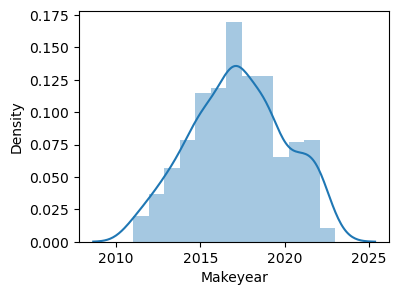

Column Name: Reg month

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['may' 'mar' 'aug' 'feb' 'jul' 'apr' 'nov' 'sep' 'jan' 'dec' 'oct' 'jun']

Number of Classes: 12

Value Counts of each class:
mar    58
oct    56
aug    55
sep    55
jul    53
apr    51
may    46
nov    46
feb    44
jan    44
jun    44
dec    41
Name: Reg month, dtype: int64

Each Class percentage:
mar    9.78
oct    9.44
aug    9.27
sep    9.27
jul    8.94
apr    8.60
may    7.76
nov    7.76
feb    7.42
jan    7.42
jun    7.42
dec    6.91
Name: Reg month, dtype: float64

Mode value: mar

*****************************************
      Visual Analysis - Pie Charts      
*****************************************

?????? Too many classes to Show ????????????????


Column Name: Reg year

*****************************************
          Descriptive Stats              
*****************************************

Mean: 2017.33
Media

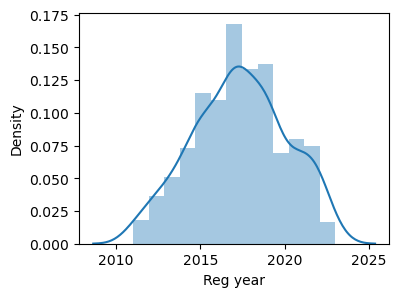

Column Name: Regnumber

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['mh01-by4993' 'mh01-by3310' 'mh43-an4332' 'mh02-cw5750' 'mh02-bz9982'
 'mh01-ch1348' 'mh02-dw2046' 'mh02-dz4140' 'mh48-p4784' 'mh02-dz7980'
 'mh04-gz7465' 'mh48-bh5207' 'mh02-dw7414' 'mh02-cd1194' 'mh02-dw1584'
 'mh05-cm9865' 'mh43-bk0324' 'mh02-ds0379' 'mh05-ea3696' 'mh02-dw8567'
 'mh02-dw2210' 'mh05-bl4775' 'mh02-ee4541' 'mh47-bk0469' 'mh02-dz9473'
 'mh12-ky4406' 'mh03-cs1294' 'mh01-cp7273' 'mh05-ea5695' 'mh47-k9210'
 'mh01-db3180' 'mh04-jb8572' 'mh43-bn0720' 'mh48-ak4289' 'mh02-ee8694'
 'mh02-eu5884' 'mh05-cv0056' 'mh43-bk0924' 'mh03-cb8150' 'mh02-cz1601'
 'mh04-jb4654' 'mh02-dj7490' 'mh47-a5677' 'mh02-ez1446' 'mh01-by7255'
 'mh02-cw7427' 'mh01-de2414' 'mh05-ds4066' 'mh01-bb1859' 'mh19-cv8147'
 'mh01-bu4389' 'mh47-q6548' 'mh05-ev6860' 'mh47-ay8383' 'mh02-ep0824'
 'mh05-cv0336' 'mh02-cz5255' 'mh05-ch4903' 'mh01-de9747' 'mh01-

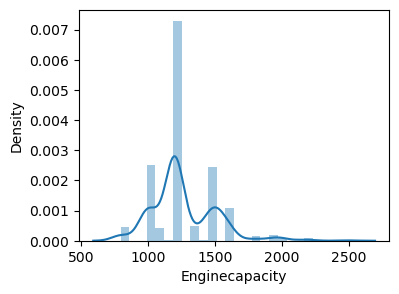

Column Name: Insurance

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['Available' 'Available on paid']

Number of Classes: 2

Value Counts of each class:
Available on paid    436
Available            157
Name: Insurance, dtype: int64

Each Class percentage:
Available on paid    73.52
Available            26.48
Name: Insurance, dtype: float64

Mode value: Available on paid

*****************************************
      Visual Analysis - Pie Charts      
*****************************************




Column Name: Sparekey

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['yes' 'no']

Number of Classes: 2

Value Counts of each class:
yes    448
no     145
Name: Sparekey, dtype: int64

Each Class percentage:
yes    75.55
no     24.45
Name: Sparekey, dtype: float64

Mode value: yes

*****************************************
      Visual Analysis - Pie Charts      
*****************************************




Column Name: Transmission

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['manual' 'automatic']

Number of Classes: 2

Value Counts of each class:
manual       410
automatic    183
Name: Transmission, dtype: int64

Each Class percentage:
manual       69.14
automatic    30.86
Name: Transmission, dtype: float64

Mode value: manual

*****************************************
      Visual Analysis - Pie Charts      
*****************************************




Column Name: KMDriven

*****************************************
          Descriptive Stats              
*****************************************

Mean: 47860.69
Median: 45029.0
Mode of the KMDriven Col: 10117.0

Min & Max: (592.0, 125956.0)
Standard Deviation: 26394.07

Skewness: 0.53
Kurtosis: -0.3

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



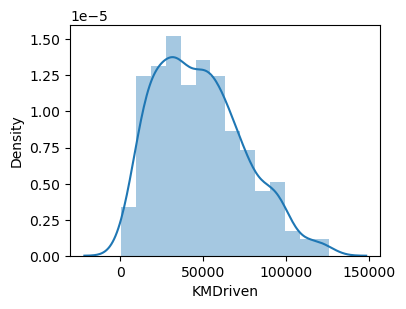

Column Name: Ownership

*****************************************
          Descriptive Stats              
*****************************************

Mean: 1.34
Median: 1.0
Mode of the Ownership Col: 1

Min & Max: (1, 3)
Standard Deviation: 0.52

Skewness: 1.17
Kurtosis: 0.31

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



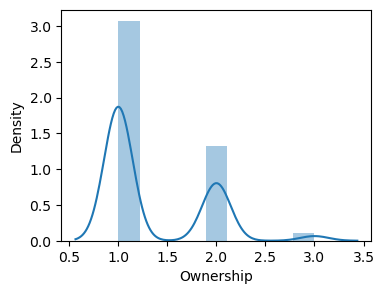

Column Name: Fueltype

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['petrol' 'diesel' 'cng']

Number of Classes: 3

Value Counts of each class:
petrol    465
diesel     74
cng        54
Name: Fueltype, dtype: int64

Each Class percentage:
petrol    78.41
diesel    12.48
cng        9.11
Name: Fueltype, dtype: float64

Mode value: petrol

*****************************************
      Visual Analysis - Pie Charts      
*****************************************




Column Name: Price(lakhs)

*****************************************
          Descriptive Stats              
*****************************************

Mean: 1.7
Median: 0.76
Mode of the Price(lakhs) Col: 0.56

Min & Max: (0.06, 7.92)
Standard Deviation: 1.86

Skewness: 1.63
Kurtosis: 1.84

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



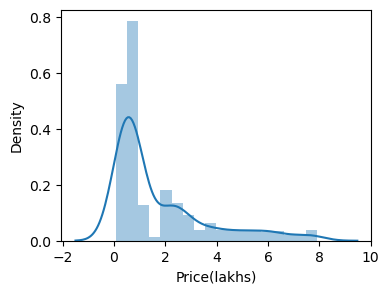

In [27]:
eda.uni_variate_analysis(data)

#### 2.2 Bi-Variant Analysis <a id='bva'>
[Back to Menu](#menu)

**N-N**

In [28]:
print("Regyear vs Price(lakhs):")

display(data[['Reg year', 'Price(lakhs)']].corr())

# corr is the stats function for correlation coefficient in pandas 

print()

print("KMDriven vs Price(lakhs):")
display(data[['KMDriven', 'Price(lakhs)']].corr())

Regyear vs Price(lakhs):


,Reg year,Price(lakhs)
Reg year,1.000000,0.202544
Price(lakhs),0.202544,1.000000



KMDriven vs Price(lakhs):


,KMDriven,Price(lakhs)
KMDriven,1.000000,-0.048433
Price(lakhs),-0.048433,1.000000


In [29]:
plt.figure(figsize=(4,3))

px.scatter(data, x='Price(lakhs)', y='Reg year', width=600, height=350)

<Figure size 400x300 with 0 Axes>

<Axes: >

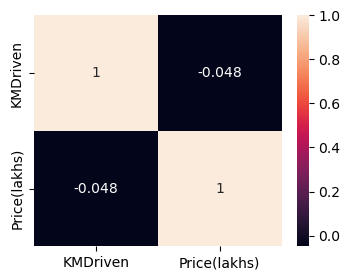

In [30]:
plt.figure(figsize=(4,3))
sns.heatmap(data[['KMDriven', 'Price(lakhs)']].corr(), annot=True)

**Insights**

- The data shows that there is a negative correlation between KMDriven and Price(lakhs) cols
     As the KMDriven increases the cost value decreases.
- The data shows that there is a positive correlation between Reg Year and Price(lakhs) cols
     As the Reg Year increases and Price(lakhs) also increases.

**N-C**

In [31]:
print("Brand vs Price(lakhs)")

display(round(data.groupby('Brand')['Price(lakhs)'].mean().sort_values(ascending=False),2))

print("Transmission vs KMDriven:")

display(round(data.groupby('Transmission')['KMDriven'].mean().sort_values(ascending=False),2))

Brand vs Price(lakhs)


Brand
mg            3.54
jeep          3.03
kia           2.54
skoda         2.33
mahindra      2.18
tata          2.02
hyundai       1.85
honda         1.80
ford          1.63
maruti        1.48
toyota        1.45
volkswagen    1.45
datsun        1.36
renault       1.21
nissan        1.03
Name: Price(lakhs), dtype: float64

Transmission vs KMDriven:


Transmission
manual       49401.78
automatic    44407.96
Name: KMDriven, dtype: float64

In [32]:
px.box(data, x="Brand", y="Price(lakhs)")

In [33]:
px.box(data, x="Transmission", y="KMDriven")

**Insights:**

- The data shows that the Toyota Brand has highest starting price in preowned cars with 6.96 lakhs Skoda Brand stands very next to Toyota Brand  has Second Highest Starting Price
- Which may be due to new versions Jeep,kia and MG has disclosed Prices as the cars in the Dataset Manual cars have driven highest kms compared to automatic transmission

**C-C**

In [34]:
print("Brand vs Insurance:")
display(pd.crosstab(data.Brand, data.Insurance, margins=True))

print()

print("Fueltype vs Transmission:")
display(pd.crosstab(data.Fueltype, data.Transmission,margins=True))

Brand vs Insurance:


Insurance,Available,Available on paid,All
Brand,,,
datsun,1,3,4
ford,2,14,16
honda,14,53,67
hyundai,37,108,145
jeep,0,10,10
kia,4,2,6
mahindra,2,11,13
maruti,58,151,209
mg,0,3,3



Fueltype vs Transmission:


Transmission,automatic,manual,All
Fueltype,,,
cng,1,53,54
diesel,17,57,74
petrol,165,300,465
All,183,410,593


**Insights:**

- Most of the cars belongs to manual transmission in petrol as fuel.
- CNG has only one(1) automatic transmission.
- Petrol variant has highest count of cars in overall dataset.
- petrol fueltype leads in both automatic and manual transmission.

#### 2.3 Multi Variate Analysis <a id='mva'>
[Back to Menu](#menu)

In [35]:
# Checking correlations between all numeric columns

data.corr()

,Makeyear,Reg year,Enginecapacity,KMDriven,Ownership,Price(lakhs)
Makeyear,1.000000,0.993248,0.056243,-0.454386,-0.208122,0.208196
Reg year,0.993248,1.000000,0.051999,-0.458961,-0.209541,0.202544
Enginecapacity,0.056243,0.051999,1.000000,0.184168,0.015369,0.229352
KMDriven,-0.454386,-0.458961,0.184168,1.000000,0.074626,-0.048433
Ownership,-0.208122,-0.209541,0.015369,0.074626,1.000000,-0.036552
Price(lakhs),0.208196,0.202544,0.229352,-0.048433,-0.036552,1.000000


* **Reg Year (date time column) vs Price(Lakhs) (numeric continuous) vs Brand (categorical nominal)**

In [36]:
# Using Scatter Chart

px.scatter(data, x = "Reg year", y="Price(lakhs)", color="Brand")

### 3. Missing Values & Outlier Handling <a id='Naou'>
    
[Back to Top](#menu)

#### 3.1 Missing Values <a id='mv'>
[Back to Menu](#menu)

In [37]:
# Checking missiong values count for each column

data.isnull().sum()

Brand              0
Model              0
Makeyear           0
Reg month          0
Reg year           0
Regnumber          0
Enginecapacity    64
Insurance          0
Sparekey           0
Transmission       0
KMDriven           0
Ownership          0
Fueltype           0
Price(lakhs)       0
dtype: int64

#### Handling Missing Values

In [38]:
from DSProjLib.MissingValues import numeric_na_replace

In [39]:
numeric_na_replace(data)

Numeric Columns:
Index(['Makeyear', 'Reg year', 'Enginecapacity', 'KMDriven', 'Ownership',
       'Price(lakhs)'],
      dtype='object')

Missing Values Count for Each Column:
Makeyear           0
Reg year           0
Enginecapacity    64
KMDriven           0
Ownership          0
Price(lakhs)       0
dtype: int64
Replacing Na Values With Column Median value........

Missing Values Count for Each Column:


Makeyear          0
Reg year          0
Enginecapacity    0
KMDriven          0
Ownership         0
Price(lakhs)      0
dtype: int64

#### 3.2 Outliers <a id='out'>
[Back to Menu](#menu)

In [40]:
import DSProjLib 

In [41]:
from DSProjLib.Outlier import outlier_detect

In [42]:
outlier_detect(data)

Column: Makeyear
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[]

Column: Reg year
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[]

Column: Enginecapacity
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[796.0, 796.0, 796.0, 796.0, 796.0, 796.0, 796.0, 796.0, 796.0, 799.0, 799.0, 799.0, 814.0, 814.0, 814.0, 814.0]

Upper Outliers:

[1798.0, 1798.0, 1798.0, 1798.0, 1798.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1997.0, 1999.0, 1999.0, 2179.0, 2179.0, 2184.0, 2494.0]

Column: KMDriven
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[122814.0, 123684.0, 125956.0]

Column: Ownership
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[]

Column: Price(lakhs)
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[5.46, 5.55, 5.58, 5.58, 5.59, 5.62, 5.66, 5.7, 5.72, 5.76, 5.82, 5.85, 5.95, 5.98, 5.99, 6.02, 6.14, 6.19, 6.24, 6.25, 6.26, 6.29, 6.31, 6.35, 6.35, 6.48, 6.65, 6.66, 6.83, 6.88, 7.0, 7.14, 7.18, 7.37, 7.41, 7.43, 7.49, 7.63, 7.69, 7.72, 7.75, 7.78, 7.82, 7.89, 7.9, 7.92]



**Handling Outliers**

In [43]:
from DSProjLib.Outlier import outlier_replacement

In [44]:
outlier_replacement(data)

Column: Makeyear
------------------------------------------------
Replacing Outliers with 5th percentile for lower Outliers, 95th percentile for Upper Outliers....
Adjust the module code for any other replacements.........

Column: Reg year
------------------------------------------------
Replacing Outliers with 5th percentile for lower Outliers, 95th percentile for Upper Outliers....
Adjust the module code for any other replacements.........

Column: Enginecapacity
------------------------------------------------
Replacing Outliers with 5th percentile for lower Outliers, 95th percentile for Upper Outliers....
Adjust the module code for any other replacements.........

Column: KMDriven
------------------------------------------------
Replacing Outliers with 5th percentile for lower Outliers, 95th percentile for Upper Outliers....
Adjust the module code for any other replacements.........

Column: Ownership
------------------------------------------------
Replacing Outliers with 5th per

In [45]:
outlier_detect(data)

Column: Makeyear
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[]

Column: Reg year
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[]

Column: Enginecapacity
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[]

Column: KMDriven
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[]

Column: Ownership
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[]

Column: Price(lakhs)
------------------------------------------------
Boxplot For Outlier Identification:


Lower Outliers:

[]

Upper Outliers:

[]



### 4. Predictive Modelling <a id='pm'>
[Back to Menu](#menu)

- Building a predictive model/trained algorithm to get the relation between one col (y) to other column (X)

    y~f(X)+e

#### 4.1 Selecting X & y <a id='xy'>
[Back to Menu](#menu)

- Selecting Output column (y) - future predtiction column & input column/columns (X) - Reference columns
    - X (indipendent variables/input columns/explanatory variables)
    - y (dependent variable/output column/rresponse column)

In [46]:
data.head()

,Brand,Model,Makeyear,Reg month,Reg year,Regnumber,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype,Price(lakhs)
0,honda,city,2015,may,2015,mh01-by4993,1497.0,Available,yes,manual,76749.0,2,petrol,4.85
1,maruti,swift,2015,mar,2015,mh01-by3310,1197.0,Available,yes,manual,76928.0,2,petrol,3.87
2,hyundai,i10,2013,aug,2013,mh43-an4332,1197.0,Available on paid,yes,manual,37955.0,1,petrol,2.92
3,hyundai,i10,2013,may,2013,mh02-cw5750,1086.0,Available,no,manual,32961.0,2,petrol,2.45
4,hyundai,i20,2011,feb,2011,mh02-bz9982,1197.0,Available,yes,manual,72357.0,3,petrol,2.21


In [47]:
x = data.drop("Price(lakhs)", axis = 1)
y = data["Price(lakhs)"]

In [48]:
print("Output Column Data (y):")
display(y.head())
print()
print("Input Columns Data (x):")
display(x.head())

Output Column Data (y):


0    4.85
1    3.87
2    2.92
3    2.45
4    2.21
Name: Price(lakhs), dtype: float64


Input Columns Data (x):


,Brand,Model,Makeyear,Reg month,Reg year,Regnumber,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype
0,honda,city,2015,may,2015,mh01-by4993,1497.0,Available,yes,manual,76749.0,2,petrol
1,maruti,swift,2015,mar,2015,mh01-by3310,1197.0,Available,yes,manual,76928.0,2,petrol
2,hyundai,i10,2013,aug,2013,mh43-an4332,1197.0,Available on paid,yes,manual,37955.0,1,petrol
3,hyundai,i10,2013,may,2013,mh02-cw5750,1086.0,Available,no,manual,32961.0,2,petrol
4,hyundai,i20,2011,feb,2011,mh02-bz9982,1197.0,Available,yes,manual,72357.0,3,petrol


In [49]:
x.head(3)

,Brand,Model,Makeyear,Reg month,Reg year,Regnumber,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype
0,honda,city,2015,may,2015,mh01-by4993,1497.0,Available,yes,manual,76749.0,2,petrol
1,maruti,swift,2015,mar,2015,mh01-by3310,1197.0,Available,yes,manual,76928.0,2,petrol
2,hyundai,i10,2013,aug,2013,mh43-an4332,1197.0,Available on paid,yes,manual,37955.0,1,petrol


In [50]:
x.to_csv("inputs.csv", index=False)

#### 4.2 Feature Engineering of x <a id='fe'>
[Back to Menu](#menu)

- Generation/Modification/Deletion/Selection of x columns/features according to y column

In [51]:
x = x.drop(("Reg month"), axis=1)

- As per data concerns Reg Month will not effect the price where are already  considering the col Reg year which is most effective 

In [52]:
x = x.drop(("Regnumber"), axis=1)

- Here we have the column Regmonth from x
- Regnumber will not effect the price

In [53]:
x = x.drop(("Makeyear"), axis = 1)

- As per the data analysis Makeyear and Regyear are same.
- Where Makeyear shows the effect on Brand new cars, but not in the case of old pre-owned cars
    - Hence we can drop the col Makeyear

In [54]:
x.head()

,Brand,Model,Reg year,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype
0,honda,city,2015,1497.0,Available,yes,manual,76749.0,2,petrol
1,maruti,swift,2015,1197.0,Available,yes,manual,76928.0,2,petrol
2,hyundai,i10,2013,1197.0,Available on paid,yes,manual,37955.0,1,petrol
3,hyundai,i10,2013,1086.0,Available,no,manual,32961.0,2,petrol
4,hyundai,i20,2011,1197.0,Available,yes,manual,72357.0,3,petrol


- We have 6 cat columns which have to be hadled and in that columns, 
    1) Insurance 2) Sparekey 3) Transmission are in binary and have option to replace as 1, 0 or directly use, Ordinal Encoder.
- Remaining Categorial columns 4) Brand 5) Model 6) Fueltype are Nominal, whaere Brand and Model are inter linked and in fuel as per data we had ve vbry low percentage of data as CNG which has lowest effect on data
- But here we can use "OneHotEncoder" directly for all the categorical columns where also satisfies

#### Encoding

- Converting all categorical data to numeric

In [55]:
x.select_dtypes("O").head()

,Brand,Model,Insurance,Sparekey,Transmission,Fueltype
0,honda,city,Available,yes,manual,petrol
1,maruti,swift,Available,yes,manual,petrol
2,hyundai,i10,Available on paid,yes,manual,petrol
3,hyundai,i10,Available,no,manual,petrol
4,hyundai,i20,Available,yes,manual,petrol


In [56]:
x.head()

,Brand,Model,Reg year,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype
0,honda,city,2015,1497.0,Available,yes,manual,76749.0,2,petrol
1,maruti,swift,2015,1197.0,Available,yes,manual,76928.0,2,petrol
2,hyundai,i10,2013,1197.0,Available on paid,yes,manual,37955.0,1,petrol
3,hyundai,i10,2013,1086.0,Available,no,manual,32961.0,2,petrol
4,hyundai,i20,2011,1197.0,Available,yes,manual,72357.0,3,petrol


In [57]:
from sklearn.preprocessing import OrdinalEncoder

ORD = OrdinalEncoder()

In [58]:
x.loc[:, ['Insurance','Sparekey','Transmission','Fueltype']]= ORD.fit_transform(x.loc[:,['Insurance','Sparekey','Transmission','Fueltype']])

In [59]:
x.head()

,Brand,Model,Reg year,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype
0,honda,city,2015,1497.0,0.0,1.0,1.0,76749.0,2,2.0
1,maruti,swift,2015,1197.0,0.0,1.0,1.0,76928.0,2,2.0
2,hyundai,i10,2013,1197.0,1.0,1.0,1.0,37955.0,1,2.0
3,hyundai,i10,2013,1086.0,0.0,0.0,1.0,32961.0,2,2.0
4,hyundai,i20,2011,1197.0,0.0,1.0,1.0,72357.0,3,2.0


In [60]:
x.select_dtypes("O").head()

,Brand,Model
0,honda,city
1,maruti,swift
2,hyundai,i10
3,hyundai,i10
4,hyundai,i20


In [61]:
#Sklearn function 

from sklearn.preprocessing import OneHotEncoder

#Defining ohe object

ohe = OneHotEncoder(sparse=True, handle_unknown='ignore')

In [62]:
ohex = ohe.fit_transform(x.select_dtypes("O")).toarray()

In [63]:
ohex = pd.DataFrame(ohex, columns=ohe.get_feature_names_out())  #converting to dataframe

In [64]:
ohex

,Brand_datsun,Brand_ford,Brand_honda,Brand_hyundai,Brand_jeep,Brand_kia,Brand_mahindra,Brand_maruti,Brand_mg,Brand_nissan,...,Model_verna,Model_virtus,Model_vitara,Model_wagon,Model_wr-v,Model_xcent,Model_xl6,Model_xuv300,Model_xuv500,Model_yaris
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
588,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
589,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
590,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
591,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [65]:
x = pd.concat([x.select_dtypes(exclude='O'), ohex], axis=1)

In [66]:
x

,Reg year,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype,Brand_datsun,Brand_ford,...,Model_verna,Model_virtus,Model_vitara,Model_wagon,Model_wr-v,Model_xcent,Model_xl6,Model_xuv300,Model_xuv500,Model_yaris
0,2015,1497.0,0.0,1.0,1.0,76749.0,2,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2015,1197.0,0.0,1.0,1.0,76928.0,2,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2013,1197.0,1.0,1.0,1.0,37955.0,1,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2013,1086.0,0.0,0.0,1.0,32961.0,2,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2011,1197.0,0.0,1.0,1.0,72357.0,3,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
588,2022,1197.0,0.0,1.0,0.0,39263.0,1,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
589,2018,1462.0,1.0,1.0,0.0,40409.0,2,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
590,2016,1197.0,0.0,0.0,1.0,25995.0,1,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
591,2018,1498.0,1.0,1.0,1.0,40167.0,2,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Final x data for modelling

In [67]:
x.head()

,Reg year,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype,Brand_datsun,Brand_ford,...,Model_verna,Model_virtus,Model_vitara,Model_wagon,Model_wr-v,Model_xcent,Model_xl6,Model_xuv300,Model_xuv500,Model_yaris
0,2015,1497.0,0.0,1.0,1.0,76749.0,2,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2015,1197.0,0.0,1.0,1.0,76928.0,2,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2013,1197.0,1.0,1.0,1.0,37955.0,1,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2013,1086.0,0.0,0.0,1.0,32961.0,2,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2011,1197.0,0.0,1.0,1.0,72357.0,3,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [68]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 593 entries, 0 to 592
Data columns (total 93 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Reg year          593 non-null    int64  
 1   Enginecapacity    593 non-null    float64
 2   Insurance         593 non-null    float64
 3   Sparekey          593 non-null    float64
 4   Transmission      593 non-null    float64
 5   KMDriven          593 non-null    float64
 6   Ownership         593 non-null    int64  
 7   Fueltype          593 non-null    float64
 8   Brand_datsun      593 non-null    float64
 9   Brand_ford        593 non-null    float64
 10  Brand_honda       593 non-null    float64
 11  Brand_hyundai     593 non-null    float64
 12  Brand_jeep        593 non-null    float64
 13  Brand_kia         593 non-null    float64
 14  Brand_mahindra    593 non-null    float64
 15  Brand_maruti      593 non-null    float64
 16  Brand_mg          593 non-null    float64
 1

- We got 4 numeric, and 4 ordinal encoded columns, 15+70 one hot encoded columns in final x data 

- 93 input columns

- **Here**,
    - 15 Columns are Brand
    - 70 Columns are car Models
   - **4 Numeric Columns,**
        - Regyear
        - Enginecapacity
        - KMDriven
        - Ownership
   - **4 Ordinal Encoded Columns are,**
        - Insurance
        - Sparekey
        - Transmission
        - Fueltype

**y data**

In [69]:
y.head()

0    4.85
1    3.87
2    2.92
3    2.45
4    2.21
Name: Price(lakhs), dtype: float64

#### 4.3 Train-Test Split of x & y <a id='tnts'>
    
[Back to Top](#menu)
    
* Dividing data into two parts, train-test
    - train part used for model building
    - test part is used for model evaluation

In [70]:
# sklearn method

from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.30, random_state=123)

In [71]:
xtrain.shape, ytrain.shape   # model training data

((415, 93), (415,))

In [72]:
xtest.shape, ytest.shape   # model evaluation data

((178, 93), (178,))

#### 4.4 Modeling/Algorithm Training on Train Data <a id='tm'>
[Back to Menu](#menu)


- Sending xtrain & ytrain data to a algorithm, where it can study the patterns and gives predictive model to generate y for future x values
- Take y data is numerical, We can apply machine learning supervised regression algorithms

- In regression we have below algorithms,



**Linear Algorithms (x data is linear to y)**

   - Linear Regression (MLR)
   - Polinomial Regression
   - Regularization Models ( If Linear Regression becomes overfit)
       - Lasso & Ridge

**Non-Linear Alogorithms ( x data is not linear to y) - ML Supervised Classification Algorithms Used for Regression**

   - KNN Regressor
   - SVM Regressor
   - Decision Tree Regressor
   - Random Forest Regressor
   - Xgboost Regressor

**Giving xtrain, ytrain data to all the above models to get better performance model**

In [73]:
pip install xgboost

In [74]:
pip install sklearn

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  python setup.py egg_info did not run successfully.
  exit code: 1
  
  [15 lines of output]
  The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
  rather than 'sklearn' for pip commands.
  
  Here is how to fix this error in the main use cases:
  - use 'pip install scikit-learn' rather than 'pip install sklearn'
  - replace 'sklearn' by 'scikit-learn' in your pip requirements files
    (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
  - if the 'sklearn' package is used by one of your dependencies,
    it would be great if you take some time to track which package uses
    'sklearn' instead of 'scikit-learn' and report it to their issue tracker
  - as a last resort, set the environment variable
    SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
  
  More information is available at
  https://github.com/scikit-learn/sklearn-pypi-package
  [end of output]
  
  note: This error originates from a subpr

* Importing Sklearn Library Models Functions

In [75]:
from sklearn.linear_model import LinearRegression # MLR
from sklearn.preprocessing import PolynomialFeatures # Poly
from sklearn.linear_model import Lasso, Ridge # Lasso & Ridge
from sklearn.neighbors import KNeighborsRegressor # KNN
from sklearn.svm import SVR # SVM
from sklearn.tree import DecisionTreeRegressor # DT
from sklearn.ensemble import RandomForestRegressor # RF
from xgboost import XGBRegressor  # xgb

- Model Object Defining

In [76]:
#Multiple Linear Regression

mlr = LinearRegression() # inside parameters - intercept (optional)

# Polynomial Regression

polyfeat = PolynomialFeatures(degree = 2) # degree is hyperparam

poly = LinearRegression()

# Lasso (L1) & Ridge (L2)

lasso = Lasso(alpha = 5) #alpha - hyperparam - penalty

ridge = Ridge(alpha = 5)

# KNN Regressor

Knn = KNeighborsRegressor(n_neighbors=5) # n_neighbors is hyperparam

# Support Vector Regressor

svr = SVR(kernel='rbf') #non-linear kernel for non-linear data

# Decision Tree Regressor

dt = DecisionTreeRegressor()

# Random Forest Regressor

rf = RandomForestRegressor(n_estimators=50) # n_estimators - hyperparam - number of decision trees

# Xgb

xgb = XGBRegressor()

**Model Training**

- Using xtrain, ytrain data
- Using fit command to train the defined model with xtrain, ytrain

#### Linear Regression

In [77]:
# Model Training

mlr.fit(xtrain, ytrain)

LinearRegression()

Model Parameters

In [78]:
mlr.coef_, mlr.intercept_

(array([ 1.45568244e-01, -4.43350950e-04, -6.63742052e-01,  1.51557072e-01,
         2.72868564e-01,  3.90446290e-06,  4.04993497e-02, -4.36946551e-02,
        -5.98536111e-01,  3.25997126e-02, -1.59921645e-01, -3.57639321e-01,
         5.52158834e-01, -1.20667904e-02,  3.42536300e-01,  6.53080927e-02,
         9.61862952e-01, -2.23949087e-01, -5.59562074e-01, -6.29020422e-01,
         4.49413986e-01,  5.15426821e-02,  8.52728905e-02, -1.24837037e+00,
         1.62194738e+00, -5.61045304e-02, -2.17498562e-02, -8.73507644e-01,
        -1.78752402e-01, -4.89985219e-01,  4.16697834e-01, -1.01430743e+00,
        -1.55303236e+00,  4.84430940e-01,  6.89311849e-01,  5.52158834e-01,
         8.87168312e-01,  1.55075346e+00,  7.70179897e-02,  1.97638271e+00,
        -1.29050659e+00,  3.25997126e-02,  6.37836073e-01, -8.19085406e-01,
         3.16411524e-01, -7.43691312e-01, -1.77635684e-15, -9.40786188e-01,
        -8.66382113e-01,  3.21289658e-01,  9.90030460e-01,  9.61862952e-01,
         3.9

In [79]:
eq = str(mlr.intercept_)

for i, j in zip(xtrain.columns,mlr.coef_):
    mx = '{}*{}'.format(i,j)
    eq = eq+") + ("+mx

In [80]:
eq

'-291.31798150511025) + (Reg year*0.14556824354411235) + (Enginecapacity*-0.00044335095028954087) + (Insurance*-0.6637420519606181) + (Sparekey*0.1515570723034061) + (Transmission*0.2728685636228675) + (KMDriven*3.90446290113311e-06) + (Ownership*0.04049934973144201) + (Fueltype*-0.04369465505217218) + (Brand_datsun*-0.5985361106872181) + (Brand_ford*0.03259971258715765) + (Brand_honda*-0.15992164526880018) + (Brand_hyundai*-0.3576393205750816) + (Brand_jeep*0.5521588341119382) + (Brand_kia*-0.01206679038373662) + (Brand_mahindra*0.34253629992874507) + (Brand_maruti*0.06530809265097584) + (Brand_mg*0.961862952029517) + (Brand_nissan*-0.22394908711517358) + (Brand_renault*-0.5595620744268044) + (Brand_skoda*-0.6290204219257782) + (Brand_tata*0.4494139864511343) + (Brand_toyota*0.05154268208294949) + (Brand_volkswagen*0.08527289047383255) + (Model_alto*-1.2483703653898242) + (Model_altroz*1.6219473753842553) + (Model_amaze*-0.056104530405148206) + (Model_ameo*-0.021749856182562338) + (Mo

#### Polynomial Regession

- Dimensionality will become more and will take heavy run time if we take all the inputs

In [81]:
xtrain.head()

,Reg year,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype,Brand_datsun,Brand_ford,...,Model_verna,Model_virtus,Model_vitara,Model_wagon,Model_wr-v,Model_xcent,Model_xl6,Model_xuv300,Model_xuv500,Model_yaris
22,2016,1373.0,1.0,0.0,1.0,63006.0,1,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
179,2012,1497.0,1.0,0.0,1.0,62671.0,1,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
157,2015,933.0,1.0,1.0,1.0,49908.0,2,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
352,2018,1373.0,0.0,1.0,1.0,67037.0,1,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
145,2021,999.0,1.0,0.0,1.0,46060.0,1,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [82]:
# Considering 5 x columns only for model training, if we consider all the x columns we will have memory error

#x_train_p = xtrain.iloc[:,0:5]
#x_test_p = xtest.iloc[:,0:5]

In [83]:
# Converting x data to poly features

x_train_poly = polyfeat.fit_transform(xtrain)
x_test_poly = polyfeat.transform(xtest)

In [84]:
x_train_poly.shape, x_test_poly.shape

((415, 4465), (178, 4465))

In [85]:
# Model Training

poly.fit(x_train_poly, ytrain)

LinearRegression()

In [86]:
# Model params

len(poly.coef_),poly.intercept_

(4465, -103091.14428992219)

#### Lasso and Ridge

In [87]:
# Model Training

lasso.fit(xtrain, ytrain), ridge.fit(xtrain, ytrain)

(Lasso(alpha=5), Ridge(alpha=5))

In [88]:
# Model params

lasso.intercept_, lasso.coef_

(-0.5581194901883384,
 array([ 0.00000000e+00,  1.94528075e-03, -0.00000000e+00,  0.00000000e+00,
         0.00000000e+00, -4.36784874e-06, -0.00000000e+00, -0.00000000e+00,
        -0.00000000e+00, -0.00000000e+00, -0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00, -0.00000000e+00,
         0.00000000e+00, -0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
         0.00000000e+00, -0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
         0.00000000e+00, -0.00000000e+00,  0.00000000e+00, -0.00000000e+00,
         0.00000000e+00, -0.00000000e+00,  0.00000000e+00, -0.00000000e+00,
        -0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00, -0.00000000e+00,  0.00000000e+00,
        -0.00000000e+00, -0.00000000e+00,  0.00000000e+00, -0.00000000e+00,
         0.00000000e+00, -0.00000000e+00,  0.00000000e+00, -0.00000000e+00,
        -0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.0000

In [89]:
ridge.intercept_, ridge.coef_

(-290.2074073719103,
 array([ 1.43952109e-01,  1.33789238e-03, -6.43551621e-01,  5.94089567e-02,
         2.91280967e-01,  3.26897861e-06, -3.36147634e-02, -5.76541249e-02,
        -8.20788407e-02, -7.75575370e-03, -3.66282410e-02,  5.62728485e-02,
         3.85077434e-01,  3.49550663e-02, -1.34287153e-02,  6.89271961e-03,
         5.06079753e-01, -1.79717713e-01, -1.86801817e-01, -4.55738742e-01,
         3.78872794e-02, -2.12930825e-02, -4.37221954e-02, -4.57029851e-01,
         8.16394330e-01, -1.33175443e-01,  1.19357482e-01, -3.90808838e-01,
         5.98022080e-02, -1.57292868e-01,  7.37693139e-02, -3.15330985e-01,
        -7.10757531e-01,  3.19005484e-01,  3.10881056e-01,  3.85077434e-01,
         2.57630687e-01,  6.13085722e-01, -5.56854079e-02,  4.91302728e-01,
        -7.00755696e-01, -7.75575370e-03,  2.89935357e-01, -1.93414433e-01,
         2.83544871e-01, -2.50787639e-01,  0.00000000e+00, -1.09986684e-01,
        -1.86044681e-01,  9.67561203e-02,  3.68816431e-01,  5.06079

#### KNN Regressor

In [90]:
# Model Training

Knn.fit(xtrain, ytrain)

KNeighborsRegressor()

In [91]:
# Model Params

Knn.get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

#### Support Vector Regression

In [92]:
# Model Training

svr.fit(xtrain, ytrain) 

SVR()

In [93]:
# Model Prams

svr.get_params()

{'C': 1.0,
 'cache_size': 200,
 'coef0': 0.0,
 'degree': 3,
 'epsilon': 0.1,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': -1,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

#### Decision Tree Regressor

In [94]:
# Model Training

dt.fit(xtrain, ytrain)

DecisionTreeRegressor()

In [95]:
# Modle params

dt.get_params()

{'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'random_state': None,
 'splitter': 'best'}

In [96]:
# Tree Visualization

from sklearn.tree import plot_tree

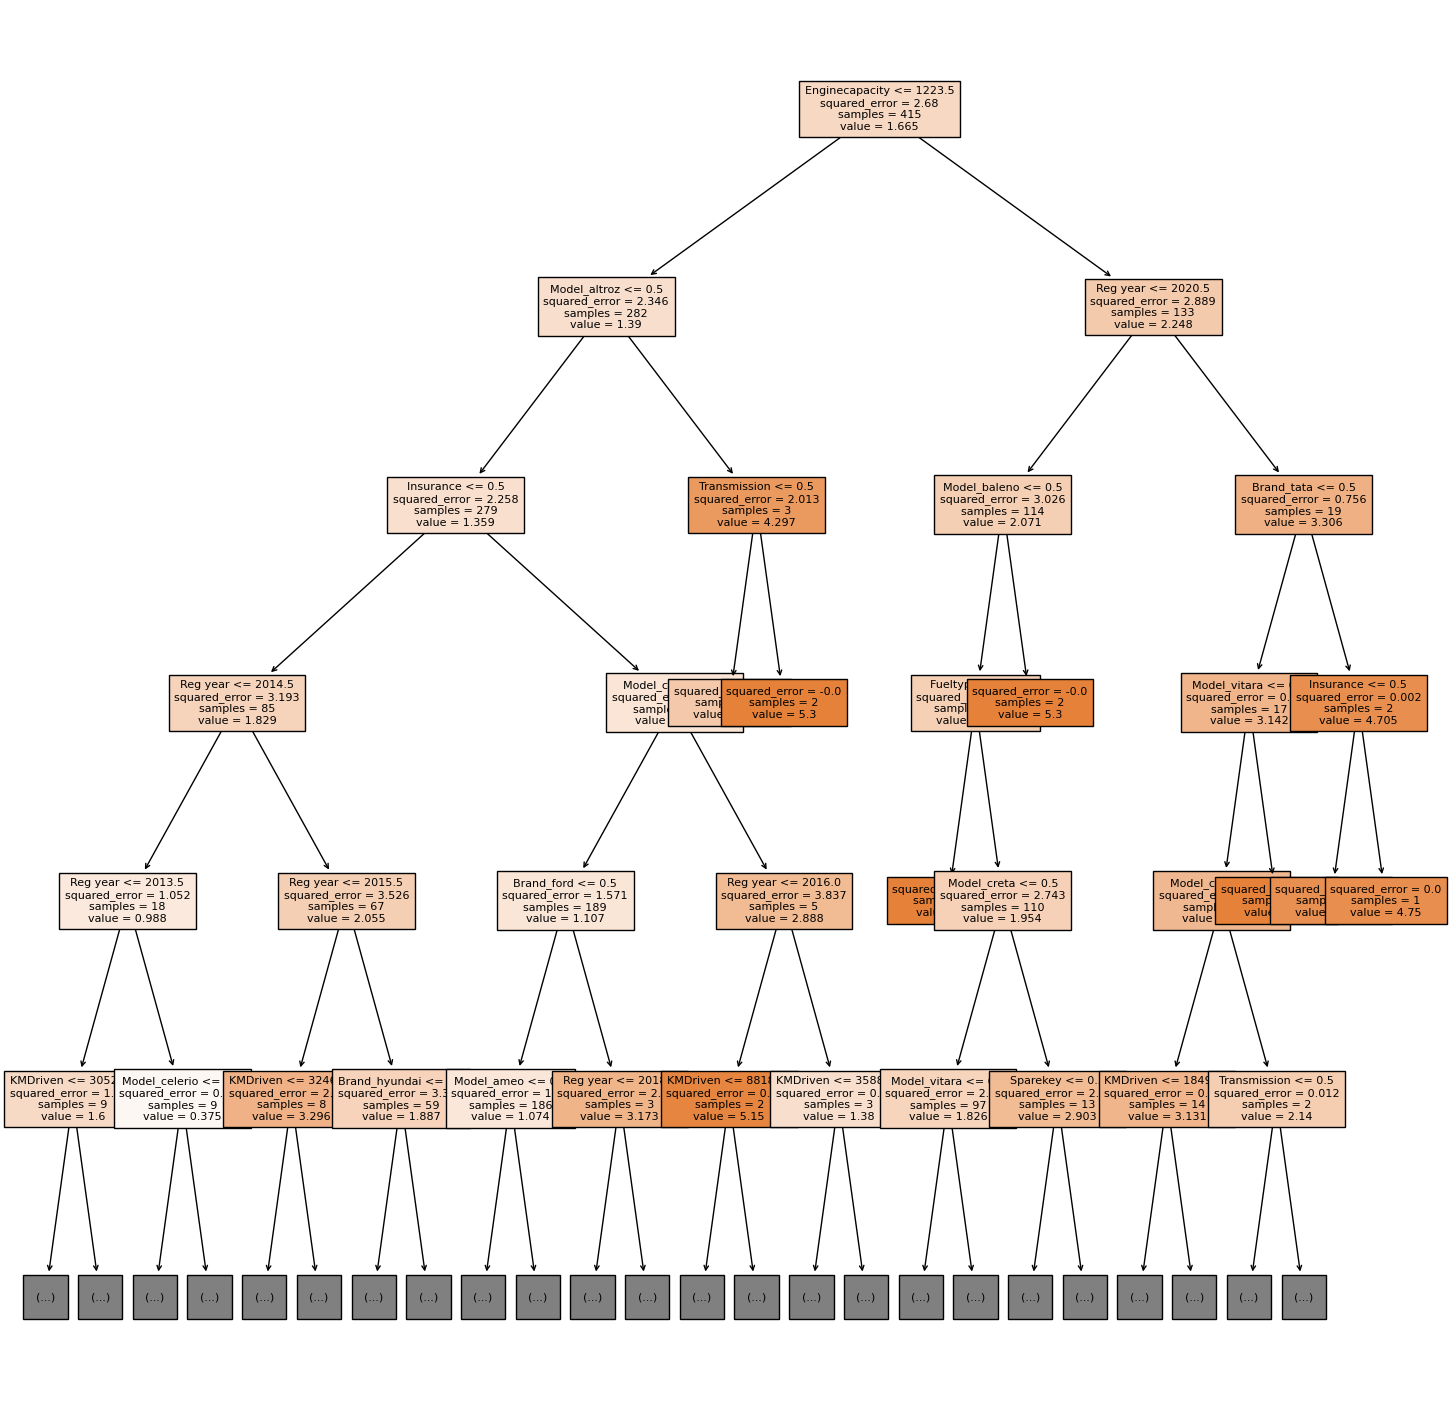

In [97]:
plt.figure(figsize=(18,18))
feature_names = list(xtrain.columns)
plot_tree(dt,filled=True,fontsize=8,feature_names=feature_names,max_depth=5)
plt.show()

#### Randomforest Regressor

In [98]:
# Model Train

rf.fit(xtrain, ytrain)

#n_estimators is the number of trees hyperparam

RandomForestRegressor(n_estimators=50)

In [99]:
# Model Params

print("Model Prams:")

print(rf.get_params())
print()
print("Columns Importance:")
print()
for i, j in zip(rf.feature_names_in_, rf.feature_importances_):
    print(i+": "+str(j))

Model Prams:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 50, 'n_jobs': None, 'oob_score': False, 'random_state': None, 'verbose': 0, 'warm_start': False}

Columns Importance:

Reg year: 0.15747129682073976
Enginecapacity: 0.11384895975975347
Insurance: 0.0430248455942023
Sparekey: 0.027857626362395912
Transmission: 0.01917644623765654
KMDriven: 0.24597963780518908
Ownership: 0.035895736177567764
Fueltype: 0.029116540620933933
Brand_datsun: 0.0008200617942890103
Brand_ford: 0.008644632281050443
Brand_honda: 0.007460451519452783
Brand_hyundai: 0.012279759698544312
Brand_jeep: 0.002846341306817714
Brand_kia: 0.002976228122119835
Brand_mahindra: 0.001135014402341832
Brand_maruti: 0.010199212803731143
Brand_mg: 0.0022861878847791426
Brand_nissan: 0.00159919607

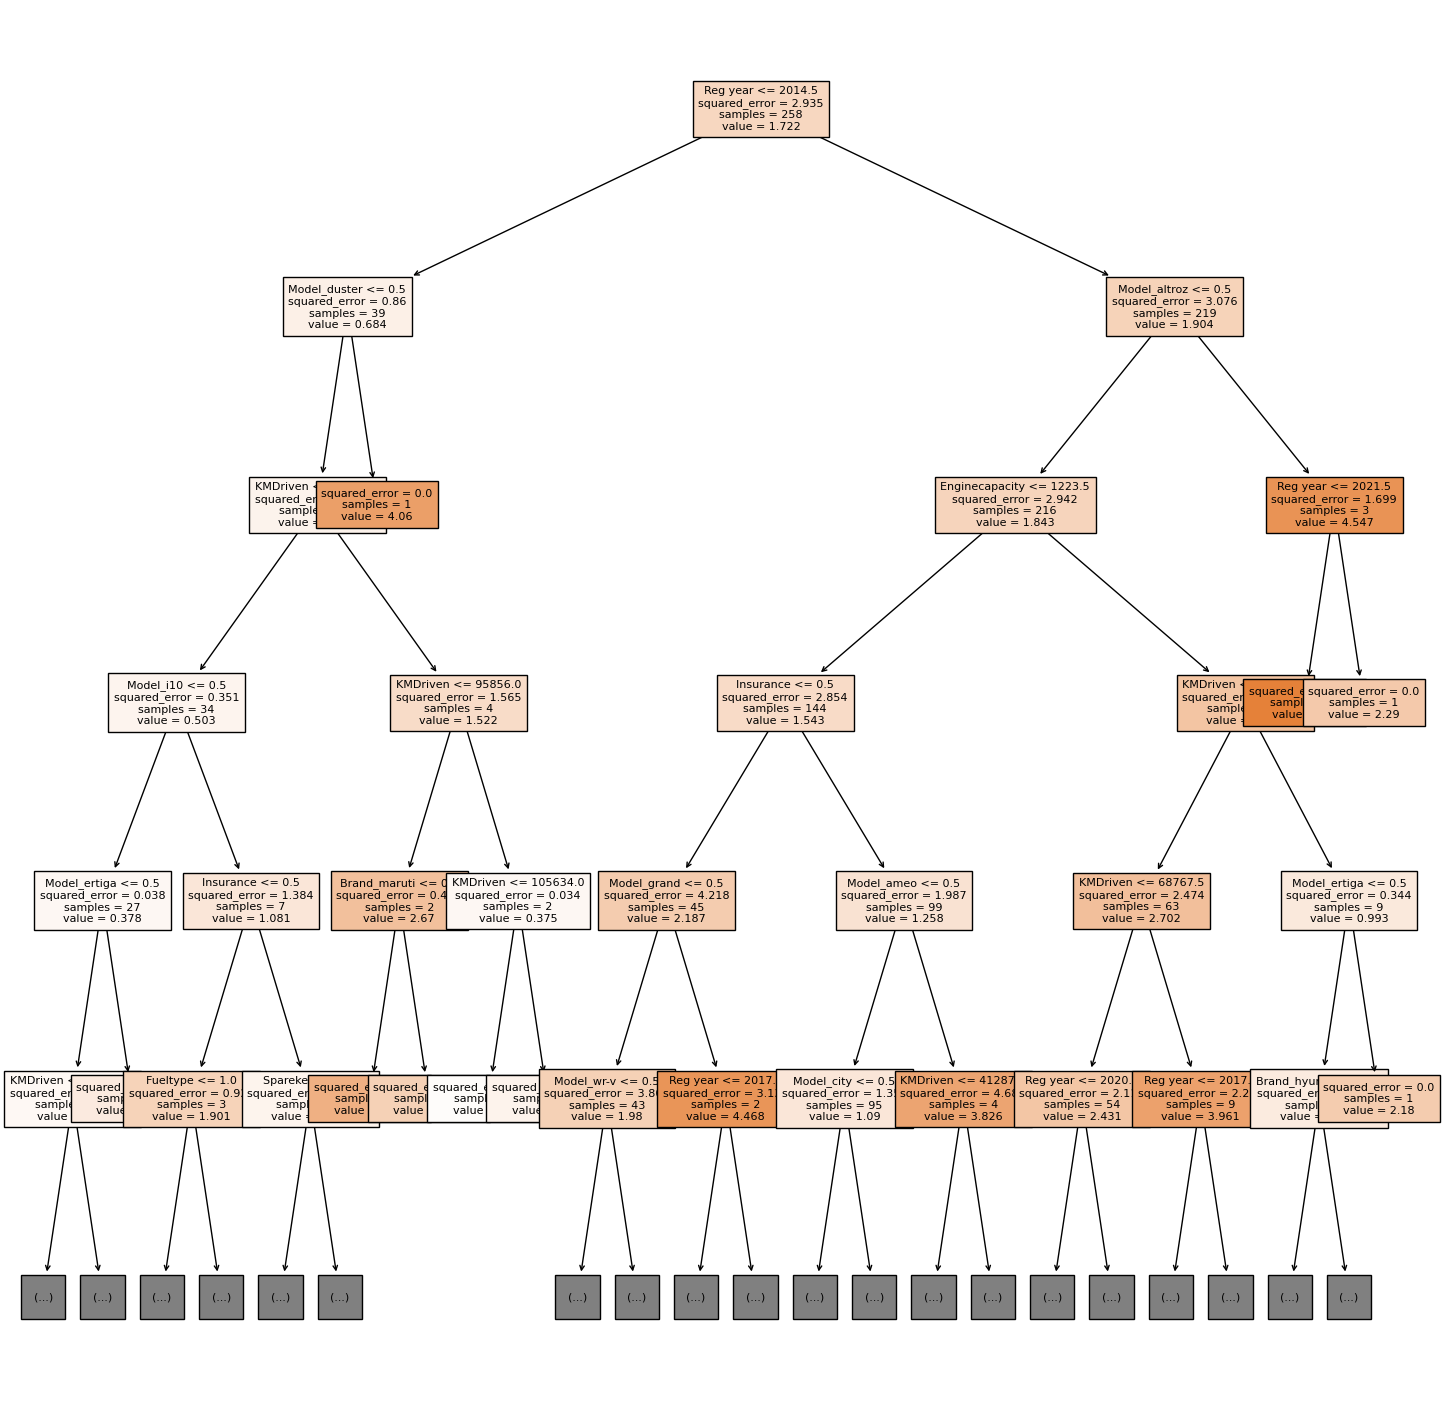

In [100]:
# Tree Visualization

from sklearn.tree import plot_tree

plt.figure(figsize=(18,18))
feature_names = list(xtrain.columns)

plot_tree(rf.estimators_[0], filled=True,fontsize=8,feature_names=feature_names, max_depth=5)
plt.show()

#### xgb Regressor

In [101]:
# Model Training

xgb.fit(xtrain, ytrain)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=None, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [102]:
xgb.get_params()

{'objective': 'reg:squarederror',
 'base_score': None,
 'booster': None,
 'callbacks': None,
 'colsample_bylevel': None,
 'colsample_bynode': None,
 'colsample_bytree': None,
 'device': None,
 'early_stopping_rounds': None,
 'enable_categorical': False,
 'eval_metric': None,
 'feature_types': None,
 'gamma': None,
 'grow_policy': None,
 'importance_type': None,
 'interaction_constraints': None,
 'learning_rate': None,
 'max_bin': None,
 'max_cat_threshold': None,
 'max_cat_to_onehot': None,
 'max_delta_step': None,
 'max_depth': None,
 'max_leaves': None,
 'min_child_weight': None,
 'missing': nan,
 'monotone_constraints': None,
 'multi_strategy': None,
 'n_estimators': None,
 'n_jobs': None,
 'num_parallel_tree': None,
 'random_state': None,
 'reg_alpha': None,
 'reg_lambda': None,
 'sampling_method': None,
 'scale_pos_weight': None,
 'subsample': None,
 'tree_method': None,
 'validate_parameters': None,
 'verbosity': None}

### Model Evaluation/Performance

- Checking Trained Model Performance on Test Data
- Using x_test data we will be getting predictions, these predictions will be compared to y_test
- To check Model Performance we can use evaluation methods
    - Error/Loss
    - Model Score
    - Bias_Variance Trade off (Underfit or Overfit
    - Cross_Val Score

**For Regression we can use these evaluation**

Performance Metric | Regression
-------|-----------
**Loss or Error**|MeanSquaredError/RMSE (For both Train and Test)
**Model Score (Evaluation)** | R2score (Coefficient of Determination)
**Bias-Variance Trade Off**|Higher error & Lower score (underfit)
--|Low Train error & High Test error (Overfit)
**Cross-Val Score**|Checking trained model performance on entire X and y data

In [103]:
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import cross_val_score

Generating predictions for xtest data

- Using predict method in trained model to get ypredictions on test data
- Comparing ypred values with ytest for loss and performance

**Single Function for all models evaluations**

In [104]:
names = ['Multiple Linear Regression', 'Polynomial Regression', 'Lasso Rgression', 'Ridge Regression', 'KNN Regressor', 'Support Vector Regressor', 'Decision Tree Regressor', 'RandomForest Regressor', 'Xgboost Regressor']

models = {'mlr':mlr, 'poly':poly, 'lasso':lasso, 'ridge':ridge, 'Knn':Knn, 'svm':svr, 'dt':dt, 'rf':rf, 'xgb':xgb}

In [105]:
x = pd.concat([xtrain, xtest], axis = 0)
y = pd.concat([ytrain, ytest], axis = 0)

In [106]:
x.shape, y.shape

((593, 93), (593,))

In [107]:
# Defining empty lists

trainRMSE = []
testRMSE = []

trainscore = []
testscore = []

fit = []

crossvalscore = []

**Short code**

In [108]:
for name, model in models.items():
        
    if name == 'poly':
        
#         ptrain = xtrain.iloc[:,0:5]
#         ptest = xtest.iloc[:,0:5]
        
        pftrain = polyfeat.transform(xtrain)
        pftest = polyfeat.transform(xtest)
        
        # RMSE , R2score
        
        trainRMSE.append(round(np.sqrt(mean_squared_error(ytrain, models[name].predict(pftrain))),2))
        testRMSE.append(round(np.sqrt(mean_squared_error(ytest, models[name].predict(pftest))), 2))
        trainscore.append(round(r2_score(ytrain, models[name].predict(pftrain)),2))
        testscore.append(round(r2_score(ytest, models[name].predict(pftest)),2))
        trscore = r2_score(ytrain, models[name].predict(pftrain))
        tescore = r2_score(ytest, models[name].predict(pftest))
        
        # Bias-Variance Trade off
        
        if trscore>=0.60 and tescore>=0.60:
            if trscore>tescore:
                if trscore-tescore>=0.10:
                    fit.append("Overfit")
                elif trscore-tescore<0.10:
                    fit.append("Goodfit")
                else:
                    fit.append('Nofit')
            elif tescore>trscore:
                if tescore-trscore>=0.10:
                    fit.append("Overfit")
                elif tescore-trscore<0.10:
                    fit.append("Goodfit")
                else:
                    fit.append('Nofit')
                    
        elif trscore<0.60 and tescore<0.60:
            if abs(trscore)==0 and abs(tescore)==0:
                fit.append("Nofit")
            else:
                fit.append("Underfit")
                           
        else:
            fit.append("Nofit")
        
        # Cross validation

        scores = cross_val_score(models[name], x, y, cv=3)
        crossvalscore.append(round(scores.mean(),2))
        
    else:
        
        # RMSE, R2score

        trainRMSE.append(round(np.sqrt(mean_squared_error(ytrain, models[name].predict(xtrain))),2))
        testRMSE.append(round(np.sqrt(mean_squared_error(ytest, models[name].predict(xtest))),2))
        trainscore.append(round(r2_score(ytrain, models[name].predict(xtrain)),2))
        testscore.append(round(r2_score(ytest, models[name].predict(xtest)),2))
        trscore = r2_score(ytrain, models[name].predict(xtrain))
        tescore = r2_score(ytest, models[name].predict(xtest))
        
        # Bias-Variance Trade off
        
        if trscore>=0.60 and tescore>=0.60:
            if trscore>tescore:
                if trscore-tescore>=0.10:
                    fit.append("Overfit")
                elif trscore-tescore<0.10:
                    fit.append("Goodfit")
                else:
                    fit.append('Nofit')
            elif tescore>trscore:
                if tescore-trscore>=0.10:
                    fit.append("Overfit")
                elif tescore-trscore<0.10:
                    fit.append("Goodfit")
                else:
                    fit.append('Nofit')
                    
        elif trscore<0.60 and tescore<0.60:
            if abs(trscore)==0 and abs(tescore)==0:
                fit.append("Nofit")
            else:
                fit.append("Underfit")
                           
        else:
            fit.append("Nofit")

        # Cross-val score
        
        scores = cross_val_score(models[name], x, y, cv=3)
        crossvalscore.append(round(scores.mean(),2))

  File "C:\Users\ACER\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\ACER\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ACER\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ACER\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


In [109]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [110]:
display(pd.DataFrame({'Model':names, 'Trainedmodel':models.values(), 'TrainRMSE':trainRMSE, 'TestRMSE':testRMSE,
             'Trainscore':trainscore, 'Testscore':testscore, 'Crossvalscore':crossvalscore, 'Fit':fit}))

,Model,Trainedmodel,TrainRMSE,TestRMSE,Trainscore,Testscore,Crossvalscore,Fit
0,Multiple Linear Regression,LinearRegression(),1.370,1.460,0.300,0.050,-0.020,Underfit
1,Polynomial Regression,LinearRegression(),0.660,1385.630,0.840,-850740.970,-0.020,Nofit
2,Lasso Rgression,Lasso(alpha=5),1.590,1.460,0.060,0.060,0.040,Underfit
3,Ridge Regression,Ridge(alpha=5),1.420,1.420,0.250,0.110,0.090,Underfit
4,KNN Regressor,KNeighborsRegressor(),1.450,1.730,0.210,-0.320,-0.230,Underfit
5,Support Vector Regressor,SVR(),1.850,1.650,-0.280,-0.200,-0.270,Underfit
6,Decision Tree Regressor,DecisionTreeRegressor(),0.000,2.110,1.000,-0.970,-0.680,Nofit
7,RandomForest Regressor,"(DecisionTreeRegressor(max_features=1.0, rando...",0.610,1.480,0.860,0.020,-0.020,Nofit
8,Xgboost Regressor,"XGBRegressor(base_score=None, booster=None, ca...",0.210,1.680,0.980,-0.250,-0.200,Nofit


#### Model Performance Improve notes (Suggestions)

* Number of classes in cat cols are huge , need to reduce them

* With Hyperparameter tuning we can increase the model performance on test

* Linear Models are not performing better, as we have majoirty of data is not linear & in one hot encoded, this need to be checked.

### 5. Realtime Predictions <a id='pred'>
[Back to Menu](#menu)    


* Using best model
    - Polynomial Regression is best fit model for the data

In [111]:
inputs = pd.read_csv("inputs.csv")

In [112]:
inputs.head()

,Brand,Model,Makeyear,Reg month,Reg year,Regnumber,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype
0,honda,city,2015,may,2015,mh01-by4993,1497.000,Available,yes,manual,76749.000,2,petrol
1,maruti,swift,2015,mar,2015,mh01-by3310,1197.000,Available,yes,manual,76928.000,2,petrol
2,hyundai,i10,2013,aug,2013,mh43-an4332,1197.000,Available on paid,yes,manual,37955.000,1,petrol
3,hyundai,i10,2013,may,2013,mh02-cw5750,1086.000,Available,no,manual,32961.000,2,petrol
4,hyundai,i20,2011,feb,2011,mh02-bz9982,1197.000,Available,yes,manual,72357.000,3,petrol


In [113]:
def predict():
    
    display(inputs.head(2))
    print()
    
    print("Enter Below Details:")
    print()
    print("Select Brand:", inputs.Brand.unique())
    brand = input()
    print()
    print("Select Model:", inputs[inputs.Brand==brand].Model.unique())
    model = input()
    print("Enter Year:")
    year = eval(input("Enter Registration Year:"))
    
    data = inputs[(inputs.Brand==brand) & (inputs.Model==model)].iloc[:, [0,1,4,6,7,8,9,10,11,12]]
    data['Reg year'] = year
    data =  data.dropna(axis=0).reset_index(drop=True)
    display(data.head())
    
    x = data.copy()
    
#     print(brand, model, year)
     # Data pre-processing
    
    x.loc[:, ['Insurance','Sparekey','Transmission','Fueltype']]= ORD.transform(x.loc[:,['Insurance','Sparekey','Transmission','Fueltype']])
    
    ohex = ohe.transform(x.select_dtypes("O")).toarray()
    ohex = pd.DataFrame(ohex, columns=ohe.get_feature_names_out())
    x = pd.concat([x.select_dtypes(exclude="O"), ohex], axis=1)

     #predictions
    
    Prices = mlr.predict(x)
    
    data['Estimated Price'] =  Prices
    
    print()
    print("Estimations: ")
    display(data)

In [114]:
predict()

,Brand,Model,Makeyear,Reg month,Reg year,Regnumber,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype
0,honda,city,2015,may,2015,mh01-by4993,1497.000,Available,yes,manual,76749.000,2,petrol
1,maruti,swift,2015,mar,2015,mh01-by3310,1197.000,Available,yes,manual,76928.000,2,petrol



Enter Below Details:

Select Brand: ['honda' 'maruti' 'hyundai' 'renault' 'tata' 'volkswagen' 'skoda' 'toyota'
 'ford' 'nissan' 'mahindra' 'datsun' 'kia' 'jeep' 'mg']
kia

Select Model: ['sonet' 'seltos']
sonet
Enter Year:
Enter Registration Year:2026


,Brand,Model,Reg year,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype
0,kia,sonet,2026,998.000,Available on paid,yes,manual,27455.000,1,petrol
1,kia,sonet,2026,1197.000,Available on paid,yes,manual,48448.000,1,petrol
2,kia,sonet,2026,1197.000,Available,yes,manual,36075.000,1,petrol



Estimations: 


,Brand,Model,Reg year,Enginecapacity,Insurance,Sparekey,Transmission,KMDriven,Ownership,Fueltype,Estimated Price
0,kia,sonet,2026,998.000,Available on paid,yes,manual,27455.000,1,petrol,2.864
1,kia,sonet,2026,1197.000,Available on paid,yes,manual,48448.000,1,petrol,2.857
2,kia,sonet,2026,1197.000,Available,yes,manual,36075.000,1,petrol,3.473
